# SHL Hiring Assessment

In [ ]:
!pip install -q openai-whisper transformers language-tool-python lightgbm librosa
!apt-get install -y -q default-jre

Reading package lists...
Building dependency tree...
Reading state information...
default-jre is already the newest version (2:1.21-75+exp1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [ ]:
!pip install -q openai-whisper language-tool-python lightgbm
!apt-get install -y -q default-jre

Reading package lists...
Building dependency tree...
Reading state information...
default-jre is already the newest version (2:1.21-75+exp1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [ ]:
import os
if not os.path.exists("/content/data/Dataset_Final/train.csv") and not os.path.exists("/content/data/train.csv"):
    !unzip -q /content/shl-hiring-assessment-2026.zip -d /content/data
!ls /content/data

Dataset_Final


In [ ]:
import os, re, warnings, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
import torch, librosa
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


## 1. Config & data loading

In [ ]:

DATA_DIR   = "/content/data/Dataset_Final"
TRAIN_CSV  = f"{DATA_DIR}/train.csv"
TEST_CSV   = f"{DATA_DIR}/test.csv"
SAMPLE_SUB = f"{DATA_DIR}/sample_submission.csv"
TRAIN_AUDIO = f"{DATA_DIR}/train"          # 769 .wav files
TEST_AUDIO  = f"{DATA_DIR}/test"           # 216 .wav files
CACHE = "cache"; os.makedirs(CACHE, exist_ok=True)
SR = 16000; SEED = 42


train = pd.read_csv(TRAIN_CSV); test = pd.read_csv(TEST_CSV); sub = pd.read_csv(SAMPLE_SUB)
print(train.shape, test.shape); display(train.head())
# Detect column names robustly
FILE_COL = [c for c in train.columns if "file" in c.lower() or "name" in c.lower()][0]
LABEL_COL = [c for c in train.columns if c != FILE_COL][0]
print("file col:", FILE_COL, "| label col:", LABEL_COL)
def wav_path(folder, name): return os.path.join(folder, name if name.endswith(".wav") else name + ".wav")

(769, 2) (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


file col: filename | label col: label


## 2. Exploratory analysis (label distribution, audio duration)

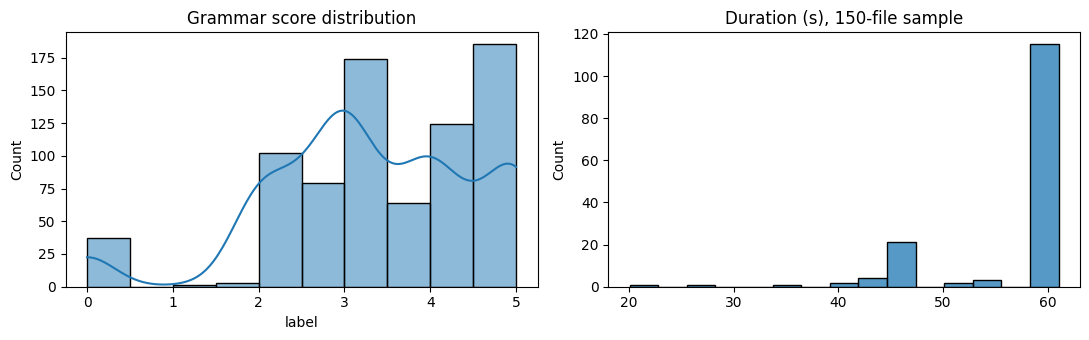

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train[LABEL_COL], bins=10, kde=True, ax=ax[0]); ax[0].set_title("Grammar score distribution")
durs = [librosa.get_duration(path=wav_path(TRAIN_AUDIO, f)) for f in train[FILE_COL][:150]]
sns.histplot(durs, bins=15, ax=ax[1]); ax[1].set_title("Duration (s), 150-file sample")
plt.tight_layout(); plt.show()
print(train[LABEL_COL].describe())

## 3. Preprocessing & ASR (Whisper)
Audio is loaded mono at 16 kHz and peak-normalised. Whisper (`small` by default; use `medium` for better accuracy if GPU allows) transcribes with `language="en"`. Transcripts are cached.

In [ ]:
import whisper
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y / (np.max(np.abs(y)) + 1e-9)

def transcribe_all(files, folder, tag, model_size="small"):
    out = f"{CACHE}/trans_{tag}.json"
    if os.path.exists(out): return json.load(open(out))
    model = whisper.load_model(model_size, device=DEVICE); res = {}
    for f in tqdm(files, desc=f"ASR {tag}"):
        r = model.transcribe(wav_path(folder, f), language="en", fp16=(DEVICE=="cuda"),
                             temperature=0, condition_on_previous_text=False)
        res[f] = {"text": r["text"].strip(),
                  "segments": [(s["start"], s["end"], s.get("no_speech_prob", 0)) for s in r["segments"]]}
    json.dump(res, open(out, "w")); return res

tr_asr = transcribe_all(train[FILE_COL].tolist(), TRAIN_AUDIO, "train")
te_asr = transcribe_all(test[FILE_COL].tolist(),  TEST_AUDIO,  "test")
train["text"] = train[FILE_COL].map(lambda f: tr_asr[f]["text"]); test["text"] = test[FILE_COL].map(lambda f: te_asr[f]["text"])
display(train[[FILE_COL, LABEL_COL, "text"]].sample(3, random_state=1))

100%|███████████████████████████████████████| 461M/461M [00:05<00:00, 93.8MiB/s]


ASR train:   0%|          | 0/769 [00:00<?, ?it/s]

ASR test:   0%|          | 0/216 [00:00<?, ?it/s]

,filename,label,text
285,audio_90.wav,4.0,The most interesting is that schools always ha...
101,audio_430.wav,4.0,My favorite hobby is always listening to music...
582,audio_5071.wav,0.0,"Oh, it's a good family. And it's a good place ..."


## 4. Feature engineering
**Text/grammar features:** LanguageTool error counts (total and per 100 words, by category), GPT-2 mean log-likelihood/perplexity, words, unique-word ratio, mean sentence length, long-word ratio, filler & repetition rates, speech rate from ASR segments.

In [ ]:
import language_tool_python
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tool = language_tool_python.LanguageTool("en-US")
gtok = GPT2TokenizerFast.from_pretrained("gpt2"); glm = GPT2LMHeadModel.from_pretrained("gpt2").to(DEVICE).eval()
FILLERS = {"um","uh","umm","uhh","er","ah","like","you know","i mean"}

@torch.no_grad()
def gpt2_nll(text):
    ids = gtok(text, return_tensors="pt", truncation=True, max_length=512).input_ids.to(DEVICE)
    if ids.shape[1] < 2: return 10.0
    return glm(ids, labels=ids).loss.item()

def text_features(text, segs, dur=55.0):
    words = re.findall(r"[A-Za-z']+", text.lower()); n = max(len(words), 1)
    sents = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    matches = tool.check(text) if text else []
    cats = pd.Series([m.category for m in matches]).value_counts() if matches else pd.Series(dtype=int)
    reps = sum(1 for a, b in zip(words, words[1:]) if a == b)
    nll = gpt2_nll(text) if text else 10.0
    speech_t = sum(e - s for s, e, _ in segs) if segs else dur
    return {"n_words": n, "uniq_ratio": len(set(words))/n, "n_sents": len(sents),
            "avg_sent_len": n/max(len(sents),1), "long_word_ratio": np.mean([len(w) > 6 for w in words]) if words else 0,
            "filler_rate": sum(w in FILLERS for w in words)/n, "repeat_rate": reps/n,
            "lt_errors": len(matches), "lt_err_per100": 100*len(matches)/n,
            "lt_grammar": cats.get("GRAMMAR", 0)/n*100, "lt_typos": cats.get("TYPOS", 0)/n*100,
            "lt_style": cats.get("STYLE", 0)/n*100, "lt_punct": cats.get("PUNCTUATION", 0)/n*100,
            "gpt2_nll": nll, "gpt2_ppl": float(np.exp(min(nll, 10))),
            "speech_rate": n/max(speech_t, 1), "pause_ratio": 1 - speech_t/dur, "n_segments": len(segs)}

def build_text_feats(df, asr, tag):
    out = f"{CACHE}/textfeat_{tag}.pkl"
    if os.path.exists(out): return pd.read_pickle(out)
    rows = [text_features(asr[f]["text"], asr[f]["segments"]) for f in tqdm(df[FILE_COL], desc=tag)]
    F = pd.DataFrame(rows); F.to_pickle(out); return F

Xt_tr = build_text_feats(train, tr_asr, "train"); Xt_te = build_text_feats(test, te_asr, "test")
display(Xt_tr.describe().T.head(10))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

train:   0%|          | 0/769 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


test:   0%|          | 0/216 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
n_words,769.0,99.433030,28.069315,1.0,81.000000,100.000000,120.000000,227.000000
uniq_ratio,769.0,0.601694,0.106412,0.0,0.543307,0.603960,0.658730,0.916667
n_sents,769.0,5.691808,2.808089,0.0,4.000000,5.000000,7.000000,16.000000
avg_sent_len,769.0,22.223028,16.258717,1.0,13.666667,17.750000,24.666667,130.000000
long_word_ratio,769.0,0.162058,0.065047,0.0,0.121212,0.153846,0.196078,0.430556
filler_rate,769.0,0.007986,0.013604,0.0,0.000000,0.000000,0.011905,0.120482
repeat_rate,769.0,0.003308,0.007445,0.0,0.000000,0.000000,0.000000,0.057554
lt_errors,769.0,2.461638,2.270485,0.0,1.000000,2.000000,3.000000,14.000000
lt_err_per100,769.0,2.498887,2.282691,0.0,0.970874,2.027027,3.361345,16.216216
lt_grammar,769.0,0.392256,0.751702,0.0,0.000000,0.000000,0.775194,6.976744


**Transcript embeddings (RoBERTa mean-pooled)** and **acoustic embeddings (wav2vec2 mean+std pooled)**.

In [ ]:
from transformers import AutoTokenizer, AutoModel, Wav2Vec2FeatureExtractor, Wav2Vec2Model

@torch.no_grad()
def text_embed(texts, tag, name="roberta-base"):
    out = f"{CACHE}/temb_{tag}.npy"
    if os.path.exists(out): return np.load(out)
    tok = AutoTokenizer.from_pretrained(name); m = AutoModel.from_pretrained(name).to(DEVICE).eval(); E = []
    for t in tqdm(texts, desc=f"text-emb {tag}"):
        b = tok(t, return_tensors="pt", truncation=True, max_length=512).to(DEVICE)
        E.append(m(**b).last_hidden_state.mean(1).squeeze().cpu().numpy())
    E = np.array(E); np.save(out, E); return E

@torch.no_grad()
def audio_embed(files, folder, tag, name="facebook/wav2vec2-base-960h"):
    out = f"{CACHE}/aemb_{tag}.npy"
    if os.path.exists(out): return np.load(out)
    fe = Wav2Vec2FeatureExtractor.from_pretrained(name); m = Wav2Vec2Model.from_pretrained(name).to(DEVICE).eval(); E = []
    for f in tqdm(files, desc=f"audio-emb {tag}"):
        y = load_audio(wav_path(folder, f))
        h = m(**{k: v.to(DEVICE) for k, v in fe(y, sampling_rate=SR, return_tensors="pt").items()}).last_hidden_state.squeeze(0)
        E.append(torch.cat([h.mean(0), h.std(0)]).cpu().numpy())
    E = np.array(E); np.save(out, E); return E

Et_tr = text_embed(train["text"].tolist(), "train"); Et_te = text_embed(test["text"].tolist(), "test")
Ea_tr = audio_embed(train[FILE_COL].tolist(), TRAIN_AUDIO, "train"); Ea_te = audio_embed(test[FILE_COL].tolist(), TEST_AUDIO, "test")
print(Xt_tr.shape, Et_tr.shape, Ea_tr.shape)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

audio-emb train:   0%|          | 0/769 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.weight    | UNEXPECTED | 
lm_head.bias      | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


audio-emb test:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 18) (769, 768) (769, 1536)


### Feature-vs-label correlations (interpretability)

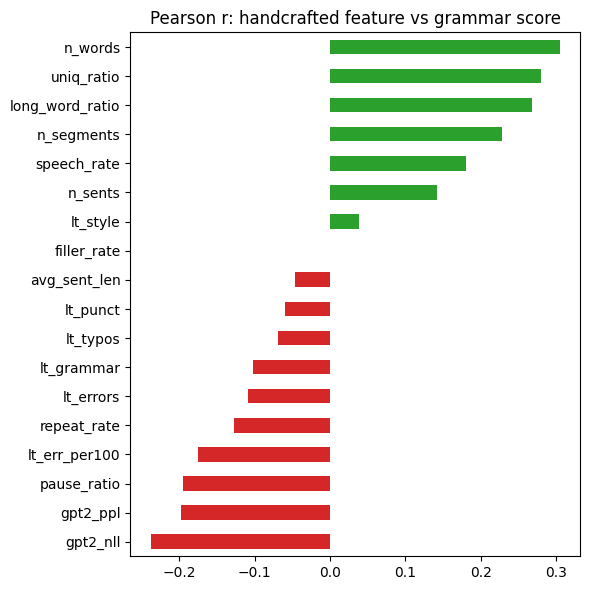

In [ ]:
y = train[LABEL_COL].values.astype(float)
corr = Xt_tr.assign(y=y).corr()["y"].drop("y").sort_values()
plt.figure(figsize=(6, 6)); corr.plot.barh(color=np.where(corr > 0, "tab:green", "tab:red"))
plt.title("Pearson r: handcrafted feature vs grammar score"); plt.tight_layout(); plt.show()

## 5. Modelling & cross-validation
Three feature-block models are trained, each evaluated with 5-fold CV (out-of-fold predictions), then blended with a non-negative linear stack fitted on the OOF predictions.

* **Handcrafted** -> Gradient Boosting
* **Text embedding + handcrafted** -> Ridge
* **Audio embedding** -> SVR (RBF)

In [ ]:
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

blocks = {
 "handcrafted_GB": (Xt_tr.values, Xt_te.values,
      lambda: GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, random_state=SEED)),
 "text_emb_Ridge": (np.hstack([Et_tr, Xt_tr.values]), np.hstack([Et_te, Xt_te.values]),
      lambda: make_pipeline(StandardScaler(), PCA(100, random_state=SEED), Ridge(alpha=50))),
 "audio_emb_SVR":  (Ea_tr, Ea_te,
      lambda: make_pipeline(StandardScaler(), PCA(100, random_state=SEED), SVR(C=3, epsilon=0.2))),
}
kf = KFold(5, shuffle=True, random_state=SEED)
oof, test_pred, full_train_pred = {}, {}, {}
for name, (Xtr, Xte, mk) in blocks.items():
    o = np.zeros(len(y)); tp = np.zeros(len(Xte))
    for tr_i, va_i in kf.split(Xtr):
        m = mk().fit(Xtr[tr_i], y[tr_i]); o[va_i] = m.predict(Xtr[va_i]); tp += m.predict(Xte)/kf.n_splits
    oof[name] = np.clip(o, 0, 5); test_pred[name] = tp
    full_train_pred[name] = np.clip(mk().fit(Xtr, y).predict(Xtr), 0, 5)
    print(f"{name:16s} CV RMSE={rmse(y, oof[name]):.3f}  CV Pearson={pearsonr(y, oof[name])[0]:.3f}")

In [ ]:
# Non-negative stacking on OOF predictions
names = list(blocks); O = np.column_stack([oof[n] for n in names])
stack = LinearRegression(positive=True).fit(O, y)
print(dict(zip(names, stack.coef_.round(3))), "intercept", round(stack.intercept_, 3))
oof_ens = np.clip(stack.predict(O), 0, 5)
train_ens = np.clip(stack.predict(np.column_stack([full_train_pred[n] for n in names])), 0, 5)
test_ens  = np.clip(stack.predict(np.column_stack([test_pred[n] for n in names])), 0, 5)

## 6. Results - RMSE on training data (REQUIRED) & CV metrics

In [ ]:
res = pd.DataFrame({
  "Model": names + ["STACKED ENSEMBLE"],
  "CV RMSE (OOF)":  [rmse(y, oof[n]) for n in names] + [rmse(y, oof_ens)],
  "CV Pearson":     [pearsonr(y, oof[n])[0] for n in names] + [pearsonr(y, oof_ens)[0]],
  "Train RMSE (fit on full train)": [rmse(y, full_train_pred[n]) for n in names] + [rmse(y, train_ens)]}).round(4)
display(res)
print(f"\n>>> TRAINING-DATA RMSE (final ensemble): {rmse(y, train_ens):.4f}")
print(f">>> Training Pearson: {pearsonr(y, train_ens)[0]:.4f}")
print(f">>> Honest generalisation estimate (5-fold CV RMSE): {rmse(y, oof_ens):.4f} | Pearson {pearsonr(y, oof_ens)[0]:.4f}")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(y, oof_ens, alpha=.4); ax[0].plot([0,5],[0,5],"r--"); ax[0].set(xlabel="True", ylabel="Predicted (OOF)", title="Predicted vs true")
sns.histplot(oof_ens - y, bins=25, kde=True, ax=ax[1]); ax[1].set_title("Residuals (OOF)")
res.set_index("Model")[["CV RMSE (OOF)","Train RMSE (fit on full train)"]].plot.bar(ax=ax[2]); ax[2].set_title("RMSE by model"); ax[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
sns.boxplot(x=np.round(y), y=oof_ens); plt.xlabel("True score (rounded)"); plt.ylabel("Predicted"); plt.title("Prediction spread per class"); plt.show()

## 7. Test predictions & submission file

In [ ]:
submission = sub.copy()
sub_label = [c for c in sub.columns if c != sub.columns[0]][0]
submission[sub.columns[0]] = test[FILE_COL].values
submission[sub_label] = test_ens
submission.to_csv("submission.csv", index=False)
display(submission.head()); print(submission[sub_label].describe())